In [2]:
%pip install seaborn

In [3]:
import seaborn as sns

print("Seaborn version:", sns.__version__)


Seaborn version: 0.13.2


In [4]:
# Step 1: Import required libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

# Load the built-in Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target and species names
df["target"] = iris.target
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [5]:
# Check number of rows and columns
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns)

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Descriptive statistics
print("\nDescriptive statistics:")
df.describe()

Dataset shape: (150, 6)

Column names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target', 'species'],
      dtype='str')

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int32
species                  str
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


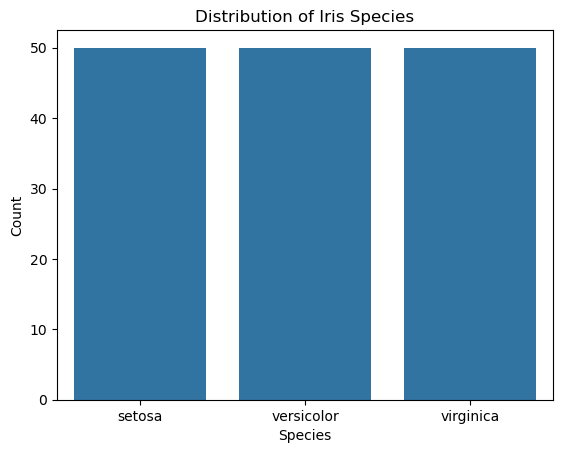

In [6]:
# Count the number of samples in each species
print(df["species"].value_counts())

# Visualize species distribution
sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

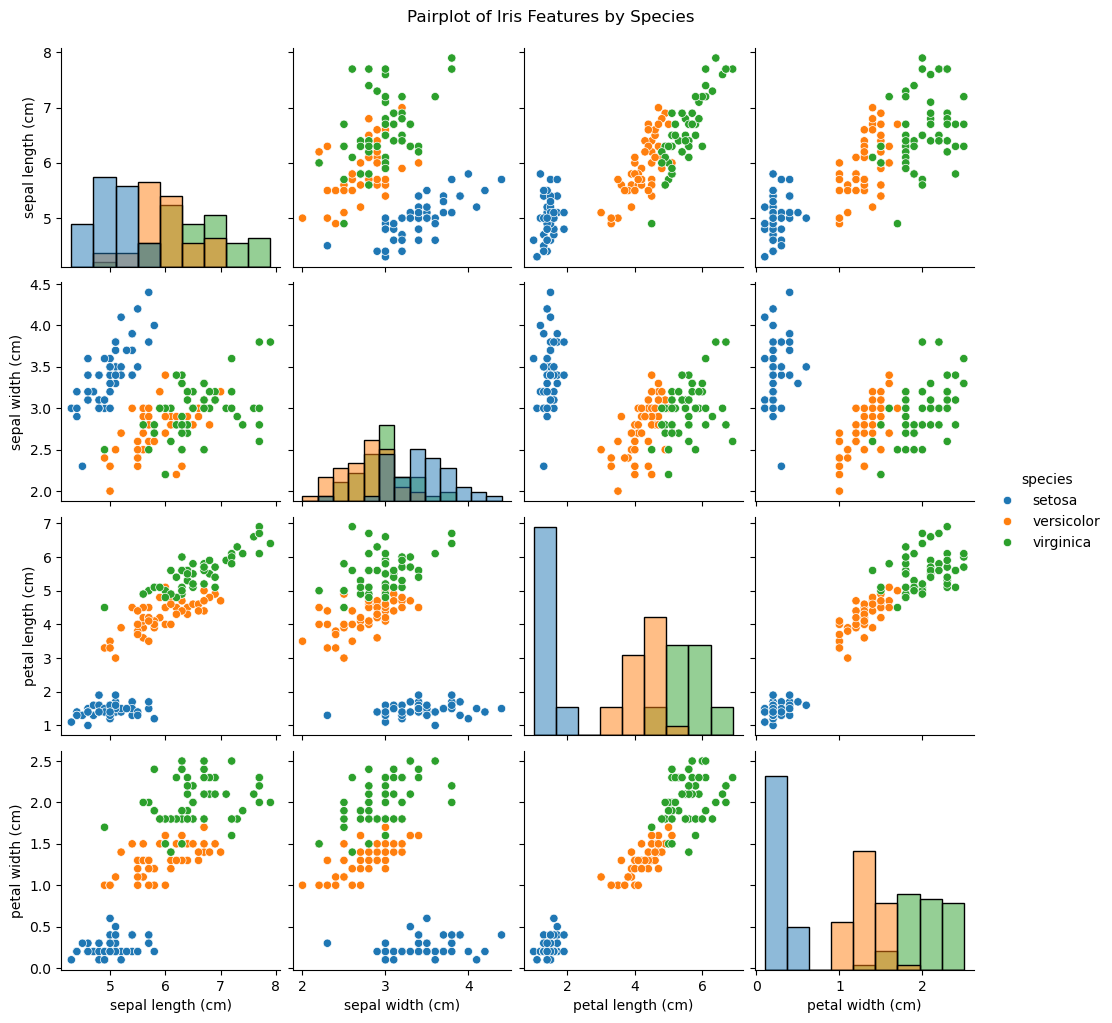

In [7]:
sns.pairplot(
    df,
    hue="species",
    vars=iris.feature_names,
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

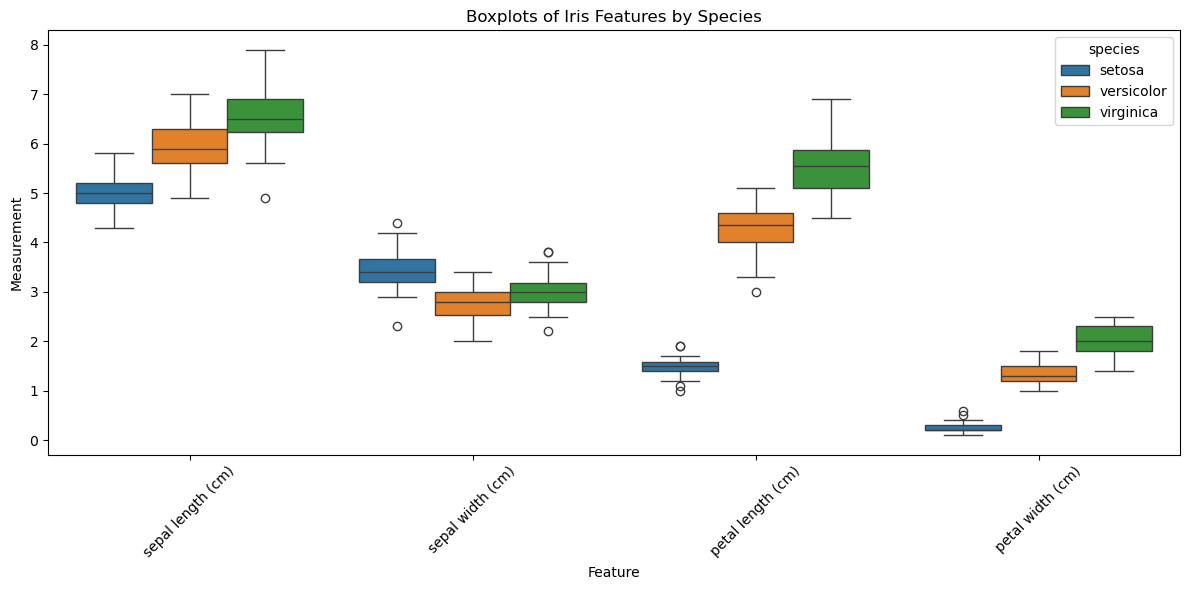

In [8]:
# Convert the dataset to long format for boxplots
df_melted = df.melt(
    id_vars="species",
    value_vars=iris.feature_names,
    var_name="Feature",
    value_name="Measurement"
)

# Create boxplots
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_melted,
    x="Feature",
    y="Measurement",
    hue="species"
)

plt.title("Boxplots of Iris Features by Species")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

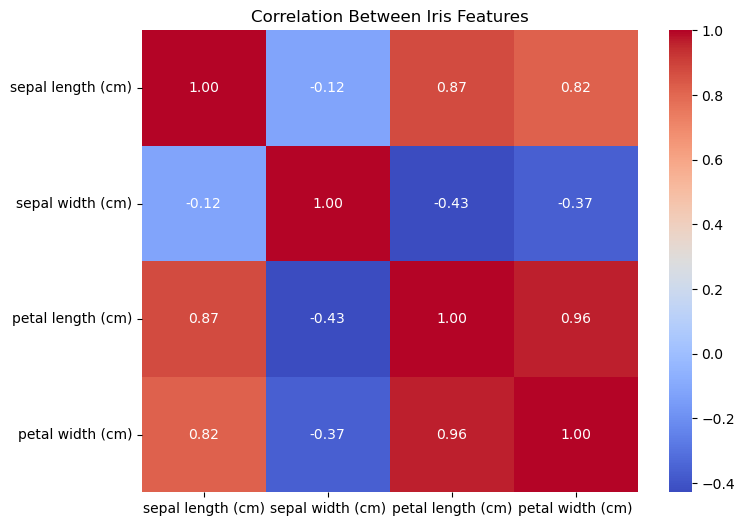

In [9]:
# Calculate correlation between numeric features
correlation = df[iris.feature_names].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Iris Features")
plt.show()

In [10]:
# Input features
X = df[iris.feature_names]

# Target labels
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Create models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
K-Nearest Neighbors trained successfully
Random Forest trained successfully


In [13]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print("=" * 50)
    print("Model:", name)
    print("Accuracy:", round(accuracy, 4))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    print("\nConfusion Matrix:")
    print(cm)

    # Classification report
    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=iris.target_names
        )
    )

Model: Logistic Regression
Accuracy: 0.9333

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Model: K-Nearest Neighbors
Accuracy: 0.9333

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93  

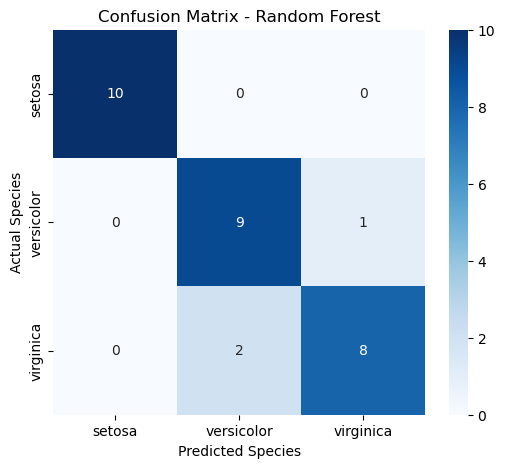

In [14]:
# Select a model to visualize
model_name = "Random Forest"
y_pred = models[model_name].predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title(f"Confusion Matrix - {model_name}")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [15]:
# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort by accuracy
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Model,Accuracy
0,Logistic Regression,0.933333
1,K-Nearest Neighbors,0.933333
2,Random Forest,0.900000


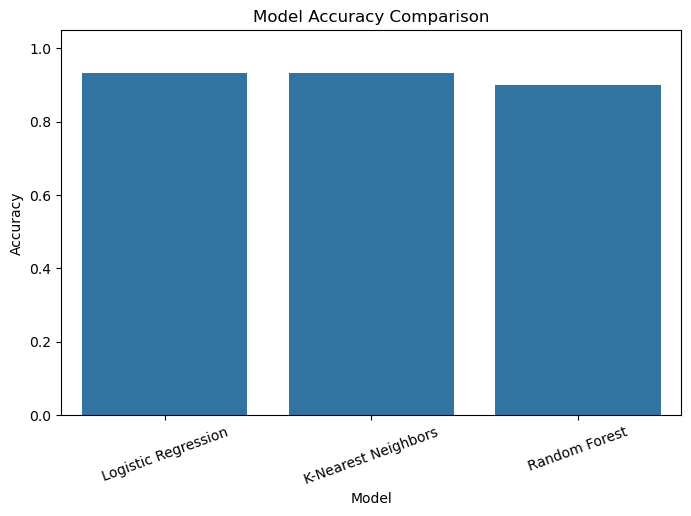

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.show()

In [17]:
# Get feature importance from Random Forest
rf_model = models["Random Forest"]

importance_df = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
3,petal width (cm),0.437185
2,petal length (cm),0.431466
0,sepal length (cm),0.116349
1,sepal width (cm),0.015000


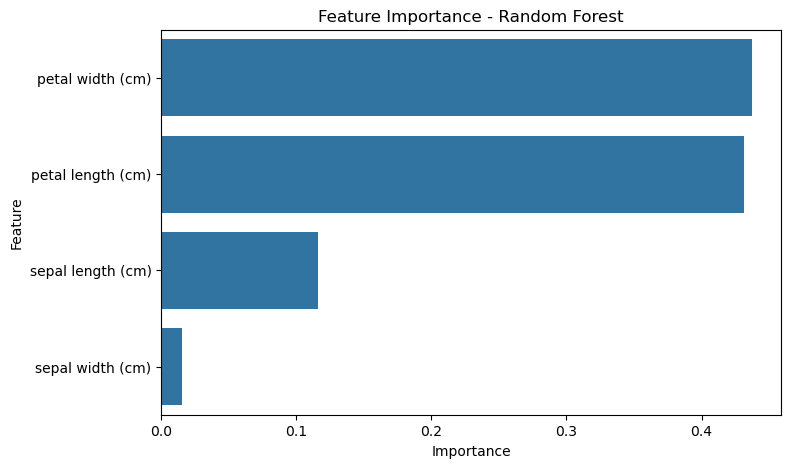

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [19]:
# Select the best model based on test accuracy
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_accuracy = results_df.iloc[0]["Accuracy"]

print("Best Model:", best_model_name)
print("Best Test Accuracy:", round(best_accuracy, 4))

Best Model: Logistic Regression
Best Test Accuracy: 0.9333


In [20]:
# Example measurements in centimeters
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict using the best model
prediction = best_model.predict(new_flower)

# Convert numeric prediction to species name
predicted_species = iris.target_names[prediction[0]]

print("Predicted Iris Species:", predicted_species)

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Predicted Iris Species: setosa
